# Lab 10 - odometry and gyroscope-based localization

go to goal run of "57" trajectory with 2 different `course` course measurements (1st - odom, 2nd - gyro):

| run | `course` |
|---|---|
| A (enc) | `course_odom = (theta_r - theta_l) * r / B` |
| B (gyro) | `course = course + gyro_inc`, `gyro_inc = (gz - b0) / (1 + s) * dt` |

log fmt:
`t_ms, ts, i, stage, theta_l, theta_r, gz, control_l, control_r, x, y, course, course_odom, course_gyro`
where:
- `ts` = gyro timestamp;
- `i` = target waypoint
- `stage`:
    -  0 = 10 s rest for `b0`;
    -  1 = moving; encoders in deg;
- `gz` in mdeg/s

In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# RUN = 'real'   # 'real' | 'sim'

# if RUN == 'real':
r, B = 0.042, 0.194
GYRO_SIGN, S_GYRO = 1, -0.0283
# else:
#     r, B = 0.028, 0.154
#     GYRO_SIGN, S_GYRO = -1, 0.0

TS_UNIT = 0.000256               # s per gyro timestamp unit
W_MAX = 286.7                    # gyro range, deg/s

X_REF = np.array([0, 0.4, 0.4, 0, 0, 0.4, 0.6, 1.0, 0.6, 0.6])
Y_REF = np.array([0, 0, 0.4, 0.4, 0.8, 0.8, 0.8, 0.8, 0.4, 0])

ENC, GYRO, REF = 'tab:blue', 'tab:orange', 'gray'
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

def wrap(a):
    return np.arctan2(np.sin(a), np.cos(a)) # angle to [-pi, pi]

## Step 1 - Ideal trajectory

Segment `k` goes from point `k-1` to point `k` (the robot logs `i = k` while driving it).

In [43]:
course_ref = np.arctan2(np.diff(Y_REF), np.diff(X_REF))
path_ref = np.hypot(np.diff(X_REF), np.diff(Y_REF))
SEG = np.arange(1, len(X_REF))

pd.DataFrame({'from, cm': list(zip(100 * X_REF[:-1], 100 * Y_REF[:-1])),
              'to, cm': list(zip(100 * X_REF[1:], 100 * Y_REF[1:])),
              'course_ref, deg': np.degrees(course_ref).round(1),
              'path_ref, cm': (100 * path_ref).round(1)}, index=pd.Index(SEG, name='segment'))

,"from, cm","to, cm","course_ref, deg","path_ref, cm"
segment,,,,
1,"(0.0, 0.0)","(40.0, 0.0)",0.0,40.0
2,"(40.0, 0.0)","(40.0, 40.0)",90.0,40.0
3,"(40.0, 40.0)","(0.0, 40.0)",180.0,40.0
4,"(0.0, 40.0)","(0.0, 80.0)",90.0,40.0
5,"(0.0, 80.0)","(40.0, 80.0)",0.0,40.0
6,"(40.0, 80.0)","(60.0, 80.0)",0.0,20.0
7,"(60.0, 80.0)","(100.0, 80.0)",0.0,40.0
8,"(100.0, 80.0)","(60.0, 40.0)",-135.0,56.6
9,"(60.0, 40.0)","(60.0, 0.0)",-90.0,40.0


## load the logs

In [52]:
COLS = ['t_ms', 'ts', 'i', 'stage', 'theta_l', 'theta_r', 'gz', 'control_l', 'control_r','x', 'y', 'course', 'course_odom', 'course_gyro']
logs = {run: pd.read_csv(f'log/{RUN}_{run}_57.csv', header=None, names=COLS) for run in 'AB'}

for run, d in logs.items():
    rest = d[d.stage == 0]
    print(f'run {run}: {d.t_ms.iloc[-1] / 1000:.1f} s, last waypoint {d.i.max()}, '
          f'b0 = {rest.gz.mean() / 1000:.3f} deg/s ({len(rest)} rest samples), '
          f'control period {d.t_ms.diff().median():.0f} ms')

run A: 29.4 s, last waypoint 9, b0 = 0.420 deg/s (250 rest samples), control period 57 ms
run B: 29.9 s, last waypoint 9, b0 = 0.399 deg/s (249 rest samples), control period 57 ms


## offline recomputation

`localize` repeats the robot's blocks (gyro angle, odometry, coordinates) on the logged raw sensors

In [53]:
def localize(d, use_gyro):
    rest = d.stage == 0
    b0 = d.gz[rest].mean()                                    # gyro offset, mdeg/s

    # odom
    theta_l, theta_r = np.radians(d.theta_l), np.radians(d.theta_r)
    path = (theta_r + theta_l) * r / 2
    course_odom = (theta_r - theta_l) * r / B

    # gyro angle block (integration starts after the 10s rest)
    dt = d.ts.diff().fillna(0) * TS_UNIT
    gyro_inc = GYRO_SIGN * np.radians((d.gz - b0) / 1000) / (1 + S_GYRO) * dt
    gyro_inc[rest] = 0
    course_gyro = gyro_inc.cumsum()

    # coordinates
    course = course_gyro if use_gyro else course_odom
    dpath = path.diff().fillna(0)
    return pd.DataFrame({'t': d.t_ms / 1000, 'i': d.i, 
                         'path': path,
                         'x': (dpath*np.cos(course)).cumsum(), 
                         'y': (dpath*np.sin(course)).cumsum(),
                         'course': course, 
                         'course_odom': course_odom,
                         'course_gyro': course_gyro})

USED = {'A': 'enc', 'B': 'gyro'}
est = {(run, src): localize(logs[run], src == 'gyro') for run in 'AB' for src in ('enc', 'gyro')}

for run in 'AB':
    d, e = logs[run], est[(run, USED[run])]
    print(f'run {run}, on robot vs offline, max difference: '
          f'x {1000 * (d.x - e.x).abs().max():.2f} mm, y {1000 * (d.y - e.y).abs().max():.2f} mm, '
          f'course {np.degrees((d.course - e.course).abs().max()):.3f} deg')

run A, on robot vs offline, max difference: x 0.00 mm, y 0.00 mm, course 0.000 deg
run B, on robot vs offline, max difference: x 0.00 mm, y 0.00 mm, course 0.000 deg


## trajectories logged on the robot

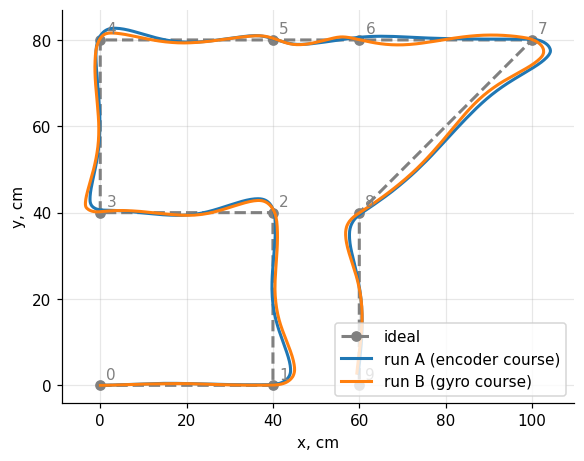

In [54]:
def draw_ideal(ax):
    ax.plot(100 * X_REF, 100 * Y_REF, 'o--', color=REF, label='ideal')
    for k in range(len(X_REF)):
        ax.annotate(k, (100 * X_REF[k], 100 * Y_REF[k]), xytext=(4, 4), textcoords='offset points', color=REF)

fig, ax = plt.subplots(figsize=(6, 5))
draw_ideal(ax)
ax.plot(100 * logs['A'].x, 100 * logs['A'].y, color=ENC, label='run A (encoder course)')
ax.plot(100 * logs['B'].x, 100 * logs['B'].y, color=GYRO, label='run B (gyro course)')
ax.set(xlabel='x, cm', ylabel='y, cm', aspect='equal')
ax.legend()
plt.show()

### The same runs seen by the other sensor (solid = on the robot, dashed = offline)

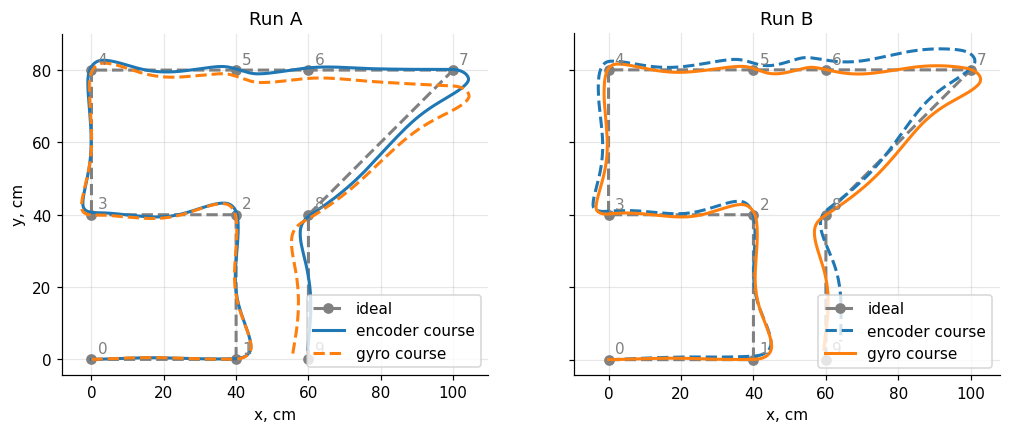

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
for ax, run in zip(axes, 'AB'):
    draw_ideal(ax)
    for src, col in (('enc', ENC), ('gyro', GYRO)):
        e = est[(run, src)]
        ax.plot(100 * e.x, 100 * e.y, color=col, ls='-' if src == USED[run] else '--',
                label=('encoder' if src == 'enc' else 'gyro') + ' course')
    ax.set(title=f'Run {run}', xlabel='x, cm', aspect='equal')
    ax.legend()
axes[0].set_ylabel('y, cm')
plt.show()

### where do the two methods disagree?

`course_gyro - course_odom` over time, turns shaded; step during a turn = slip or wrong `B` (or gyro scale factor); slow slope = gyro bias

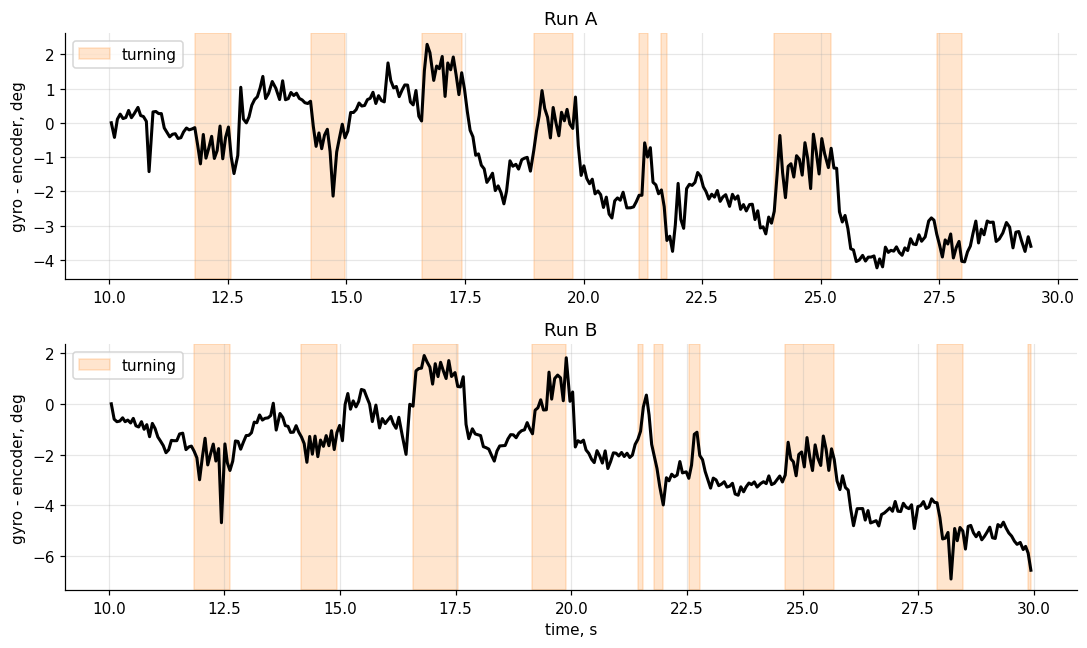

In [60]:
def turning(d):
    v = (d.control_r + d.control_l) / 2          # fwd part of the wheel commands
    w = (d.control_r - d.control_l) / 2          # turning part
    return (d.stage == 1) & (w.abs() > v.abs())

fig, axes = plt.subplots(2, 1, figsize=(10, 6))
for ax, run in zip(axes, 'AB'):
    d, e = logs[run], est[(run, USED[run])]
    moving = d.stage == 1
    ax.plot(e.t[moving], np.degrees(e.course_gyro - e.course_odom)[moving], color='k')
    ax.fill_between(e.t, 0, 1, where=turning(d), color=GYRO, alpha=0.2, transform=ax.get_xaxis_transform(), label='turning')
    ax.set(title=f'Run {run}', ylabel='gyro - encoder, deg')
    ax.legend(loc='upper left')
axes[1].set_xlabel('time, s')
plt.tight_layout()
plt.show()

## Step 4.3 - course over time against the `course_ref` staircase

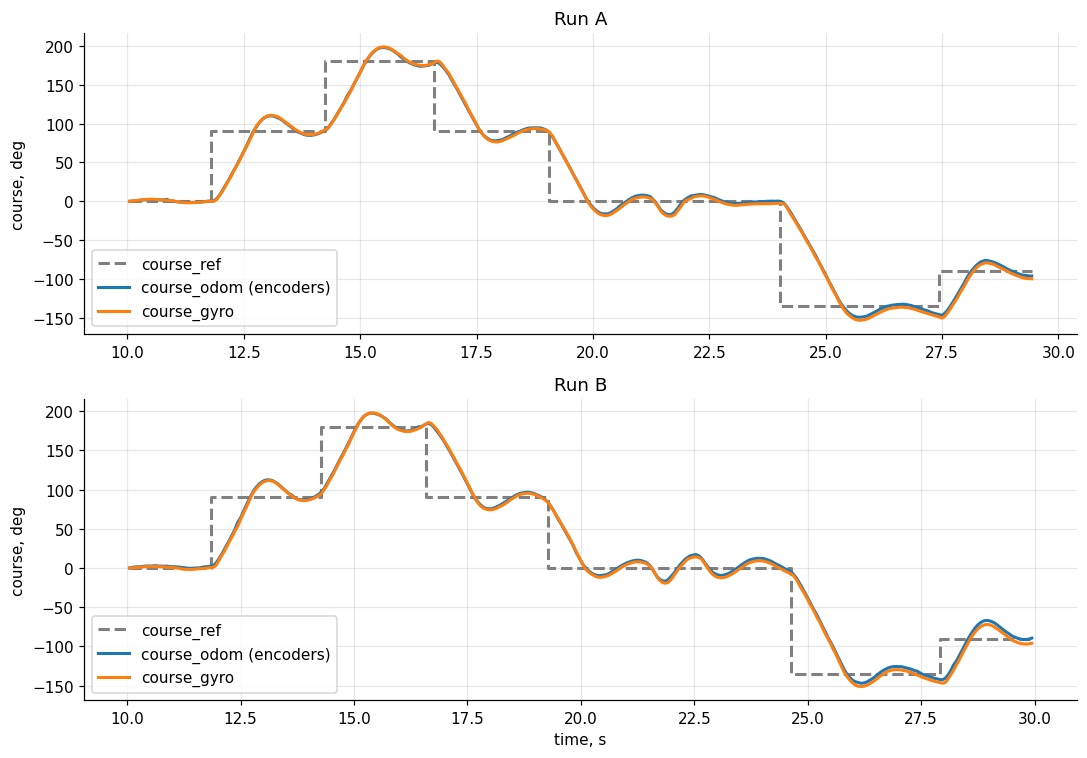

In [71]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7))
for ax, run in zip(axes, 'AB'):
    d, e = logs[run], est[(run, USED[run])]
    m = d.stage == 1
    ax.step(e.t[m], np.degrees(course_ref[d.i[m] - 1]), where='post', color=REF, ls='--', label='course_ref')
    ax.plot(e.t[m], np.degrees(e.course_odom[m]), color=ENC, label='course_odom (encoders)')
    ax.plot(e.t[m], np.degrees(e.course_gyro[m]), color=GYRO, label='course_gyro')
    ax.set(title=f'Run {run}', ylabel='course, deg')
    ax.legend(loc='lower left')
axes[1].set_xlabel('time, s')
plt.tight_layout()
plt.show()

## steps 4.3 / 4.4 - course and path per segment

- `course` of segment = mean course while **driving** it (turning rows left out), `d_course = course - course_ref`.
- `path` of segment = encoder path from the end of the previous segment to the end of this one, `d_path = path - path_ref`.
- `dist` = largest sideways distance from the line of the segment (used in Step 4.5)
- floor even with perfect sensors: the robot stops within `threshold` = 4cm of waypoint, so segment can end up to 4cm short and the next one starts up to atan(4/40) = 6deg off `course_ref`.

In [65]:
def per_segment(run, src):
    d, e = logs[run], est[(run, src)]
    moving = d.stage == 1
    driving = moving & ~turning(d)

    course = e[driving].groupby('i').course.mean()
    end_path = e[moving].groupby('i').path.last()
    path = end_path.diff().fillna(end_path.iloc[0])  # path starts at 0

    # sideways distance of every point from the line of its segment
    k = e.i - 1
    dx, dy = np.diff(X_REF)[k], np.diff(Y_REF)[k]
    side = (dx * (e.y - Y_REF[k]) - dy * (e.x - X_REF[k])) / np.hypot(dx, dy)
    dist = side[moving].abs().groupby(e.i[moving]).max()

    return pd.DataFrame({'course': course, 'd_course': wrap(course - course_ref[course.index - 1]),
                         'path': path, 'd_path': path - path_ref[path.index - 1], 'dist': dist})

S = {key: per_segment(*key) for key in est}
A, Bs = S[('A', 'enc')], S[('B', 'gyro')]
deg = np.degrees

table = pd.DataFrame({
    'course_ref, deg': deg(course_ref).round(1),
    'course enc, deg': deg(A.course).round(1).values,
    'course gyro, deg': deg(Bs.course).round(1).values,
    'd_course enc / gyro, deg': [f'{a:+.1f} / {b:+.1f}' for a, b in zip(deg(A.d_course), deg(Bs.d_course))],
    'path_ref, cm': (100 * path_ref).round(1),
    'path enc, cm': (100 * A.path).round(1).values,
    'path gyro, cm': (100 * Bs.path).round(1).values,
    'd_path enc / gyro, cm': [f'{100 * a:+.1f} / {100 * b:+.1f}' for a, b in zip(A.d_path, Bs.d_path)],
}, index=pd.Index(SEG, name='Seg.')).astype(object)

table.loc['summary'] = ['', '', '',
                        f'mean abs: {deg(A.d_course.abs()).mean():.2f} / {deg(Bs.d_course.abs()).mean():.2f}',
                        round(100 * path_ref.sum(), 1), round(100 * A.path.sum(), 1), round(100 * Bs.path.sum(), 1),
                        f'{100 * (A.path.sum() - path_ref.sum()):+.1f} / {100 * (Bs.path.sum() - path_ref.sum()):+.1f} '
                        f'({100 * (A.path.sum() / path_ref.sum() - 1):+.1f} % / {100 * (Bs.path.sum() / path_ref.sum() - 1):+.1f} %)']
table

,"course_ref, deg","course enc, deg","course gyro, deg","d_course enc / gyro, deg","path_ref, cm","path enc, cm","path gyro, cm","d_path enc / gyro, cm"
Seg.,,,,,,,,
1,0.0,0.4,0.3,+0.4 / +0.3,40.0,36.6,37.3,-3.4 / -2.7
2,90.0,95.7,97.4,+5.7 / +7.4,40.0,42.8,43.4,+2.8 / +3.4
3,180.0,184.3,184.4,+4.3 / +4.4,40.0,42.1,42.0,+2.1 / +2.0
4,90.0,87.3,86.0,-2.7 / -4.0,40.0,41.2,42.7,+1.2 / +2.7
5,0.0,-4.5,-1.2,-4.5 / -1.2,40.0,42.6,41.9,+2.6 / +1.9
6,0.0,-1.1,0.2,-1.1 / +0.2,20.0,19.5,19.6,-0.5 / -0.4
7,0.0,0.4,-1.0,+0.4 / -1.0,40.0,40.9,40.4,+0.9 / +0.4
8,-135.0,-139.3,-138.9,-4.3 / -3.9,56.6,63.2,61.9,+6.6 / +5.3
9,-90.0,-86.7,-84.6,+3.3 / +5.4,40.0,41.9,42.2,+1.9 / +2.2


### final position and course errors (relative to the last waypoint)

In [74]:
rows = []
for (run, src), e in est.items():
    end = e.iloc[-1]
    rows.append({'run': run, 'course from': ('encoders' if src == 'enc' else 'gyro') + (' (on robot)' if src == USED[run] else ' (offline)'),
                 'final x, cm': round(100 * end.x, 1), 'final y, cm': round(100 * end.y, 1),
                 'position error, cm': round(100 * np.hypot(end.x - X_REF[-1], end.y - Y_REF[-1]), 1),
                 'course error, deg': round(deg(wrap(end.course - course_ref[-1])), 1)})
pd.DataFrame(rows).set_index(['run', 'course from'])

final x, cm  final y, cm  position error, cm  \
run course from                                                         
A   encoders (on robot)         59.8          2.8                 2.8   
    gyro (offline)              55.6          1.0                 4.6   
B   encoders (offline)          64.1          5.1                 6.5   
    gyro (on robot)             59.4          2.8                 2.9   

                         course error, deg  
run course from                             
A   encoders (on robot)               -6.1  
    gyro (offline)                    -9.7  
B   encoders (offline)                 0.6  
    gyro (on robot)                   -6.0

## error growth over the segments (filled = on the robot, open = offline)

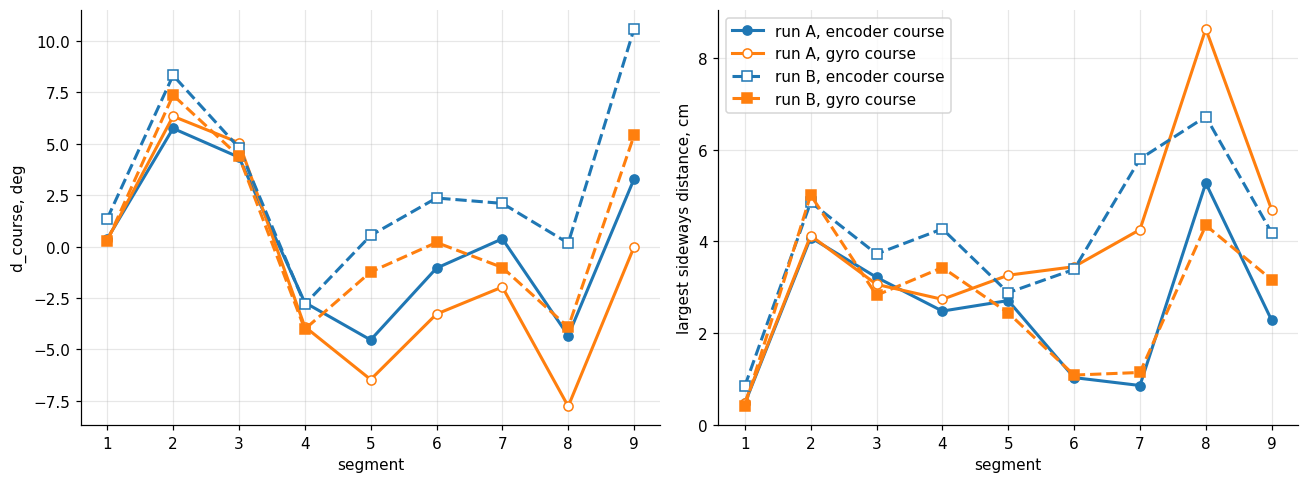

In [75]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for (run, src), s in S.items():
    col = ENC if src == 'enc' else GYRO
    style = dict(color=col, ls='-' if run == 'A' else '--', marker='o' if run == 'A' else 's',
                 mfc=col if src == USED[run] else 'white', label=f"run {run}, {'encoder' if src == 'enc' else 'gyro'} course")
    axes[0].plot(s.index, deg(s.d_course), **style)
    axes[1].plot(s.index, 100 * s.dist, **style)
axes[0].set(xlabel='segment', ylabel='d_course, deg', xticks=SEG)
axes[1].set(xlabel='segment', ylabel='largest sideways distance, cm', xticks=SEG)
axes[1].legend()
plt.tight_layout()
plt.show()

## which error source?

- turns: course change of each segment from the encoders and from the gyro. If the ratio encoder/gyro is the same for every turn, the error is systematic (wrong `B`, or the gyro scale factor);
- `B_eff = B * encoders / gyro` is the wheel base that would make them agree. If the ratio scatters, it is wheel slip.
- Saturation: the fastest turn against the gyro range `W_MAX`.
- Bias: how much the offset changes within the 10s rest (first 5s vs last 5s). Over the run this becomes a slow course drift.

In [76]:
rows = []
for run in 'AB':
    e = est[(run, USED[run])]
    end = e[logs[run].stage == 1].groupby('i').last()
    turn_enc = end.course_odom.diff().fillna(end.course_odom.iloc[0])
    turn_gyro = end.course_gyro.diff().fillna(end.course_gyro.iloc[0])
    for k in end.index[turn_gyro.abs() > np.radians(20)]:              # segments that start with a turn
        rows.append({'run': run, 'segment': k, 'gyro, deg': deg(turn_gyro[k]).round(1),
                     'encoders, deg': deg(turn_enc[k]).round(1),
                     'encoders - gyro, deg': deg(turn_enc[k] - turn_gyro[k]).round(1),
                     'B_eff, cm': (100 * B * turn_enc[k] / turn_gyro[k]).round(1)})
turns = pd.DataFrame(rows).set_index(['run', 'segment'])
display(turns)
print(f"B_eff = {turns['B_eff, cm'].mean():.1f} +- {turns['B_eff, cm'].std():.1f} cm (B used: {100 * B:.1f} cm)")

for run, d in logs.items():
    b0 = d.gz[d.stage == 0].mean()
    fastest = (d.gz[d.stage == 1] - b0).abs().max() / 1000
    rest = d[d.stage == 0]
    first, last = rest.gz[rest.t_ms < 5000].mean() / 1000, rest.gz[rest.t_ms >= 5000].mean() / 1000
    T = (d.t_ms.iloc[-1] - rest.t_ms.iloc[-1]) / 1000
    print(f'run {run}: fastest turn {fastest:.0f} deg/s (range {W_MAX:.0f}); '
          f'b0 first 5 s {first:.3f}, last 5 s {last:.3f} deg/s -> {abs(last - first) * T:.1f} deg over the {T:.0f} s run')

gyro, deg  encoders, deg  encoders - gyro, deg  B_eff, cm
run segment                                                           
A   2             89.9           89.2                  -0.7       19.2
    3             86.7           87.0                   0.4       19.5
    4            -85.5          -85.1                   0.4       19.3
    5            -93.6          -92.9                   0.8       19.2
    8           -145.2         -145.3                  -0.1       19.4
    9             48.2           48.9                   0.8       19.7
B   2             92.1           92.0                  -0.1       19.4
    3             88.4           86.8                  -1.6       19.1
    4            -94.2          -94.0                   0.2       19.4
    5            -86.5          -86.6                  -0.1       19.4
    8           -139.6         -138.8                   0.8       19.3
    9             49.3           52.0                   2.7       20.5

B_eff = 19.5 +- 0.4 cm (B used: 19.4 cm)
run A: fastest turn 120 deg/s (range 287); b0 first 5 s 0.432, last 5 s 0.409 deg/s -> 0.4 deg over the 19 s run
run B: fastest turn 123 deg/s (range 287); b0 first 5 s 0.409, last 5 s 0.389 deg/s -> 0.4 deg over the 20 s run


## Short analysis

- course vs path: both runs are about equally close to the ideal: mean |`d_course`| 3.0° (A) / 3.1° (B), total path +4.0 % / +4.2 %. Path errors are the same because path comes from the encoders in both runs. Course errors are small for both sensors; most of `d_course` comes from the controller (turn overshoot of 15–20°, 4 cm acceptance radius), not from the sensor.
- error sources: `B` is right and slip is small: `B_eff` = 19.5 ± 0.4 cm vs `B` = 19.4 cm (worst: last turn in run B, 2.7°). Gyro: no saturation (max 123 of 287 deg/s), bias change ~0.02 deg/s → ~0.4° per run. The two sensors drift apart slowly while driving straight: 3.6° (A) / 6.6° (B) at the end. Seen by the other sensor, the final error is 4.6 cm (A) / 6.5 cm (B).
- no floor measurement: the other sensor is the only reference, so an error in `r` can't be seen.
- combining: complementary filter `course = 0.01 * course_odom + 0.99 * (course + gyro_inc)`: the gyro handles fast changes (turns), the encoders slowly pull it back against gyro drift (Lab 11).
